In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.xls")

# Display the first five rows
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Information about columns and data types
print("\nDataset information:")
df.info()

# Statistical summary of numerical columns
print("\nStatistical summary:")
display(df.describe())

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [3]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("\nDuplicate customer IDs:", df["customerID"].duplicated().sum())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0

Duplicate customer IDs: 0


In [4]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove unnecessary whitespace from string columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing values after conversion:")
print(df_clean.isnull().sum())

# Examine the rows with missing TotalCharges
display(df_clean[df_clean["TotalCharges"].isnull()])

# Check tenure for these customers
print(
    "Tenure of customers with missing TotalCharges:",
    df_clean.loc[
        df_clean["TotalCharges"].isnull(),
        "tenure"
    ].tolist()
)

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Tenure of customers with missing TotalCharges: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [5]:
# Fill missing TotalCharges with 0 for zero-tenure customers
mask = (
    df_clean["TotalCharges"].isnull()
    & (df_clean["tenure"] == 0)
)

df_clean.loc[mask, "TotalCharges"] = 0

# Check whether any missing TotalCharges remain
print(
    "Remaining missing TotalCharges:",
    df_clean["TotalCharges"].isnull().sum()
)

# Check missing values across the entire dataset
print("\nMissing values in all columns:")
print(df_clean.isnull().sum())

Remaining missing TotalCharges: 0

Missing values in all columns:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
# Check duplicates
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Check unique customer IDs
print(
    "Unique customer IDs:",
    df_clean["customerID"].nunique()
)

print("Dataset shape after duplicate removal:", df_clean.shape)

Duplicate rows before cleaning: 0
Unique customer IDs: 7043
Dataset shape after duplicate removal: (7043, 21)


In [7]:
# Identify categorical columns
categorical_cols = df_clean.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical columns:\n")

for col in categorical_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))

Categorical columns:


customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     30

In [8]:
# Create a copy for model preparation
df_model = df_clean.copy()

# Remove customerID from model features
df_model = df_model.drop(columns=["customerID"])

# Encode the target variable
df_model["Churn"] = df_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Identify categorical feature columns
categorical_features = df_model.drop(
    columns=["Churn"]
).select_dtypes(include="object").columns.tolist()

# Apply one-hot encoding
df_model = pd.get_dummies(
    df_model,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Display the encoded dataset
display(df_model.head())

print("Original cleaned dataset shape:", df_clean.shape)
print("Encoded modelling dataset shape:", df_model.shape)

print("\nData types after encoding:")
print(df_model.dtypes.value_counts())

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


Original cleaned dataset shape: (7043, 21)
Encoded modelling dataset shape: (7043, 31)

Data types after encoding:
int64      29
float64     2
Name: count, dtype: int64


In [9]:
# Check missing values
print("Total missing values:", df_model.isnull().sum().sum())

# Check duplicates
print("Duplicate rows:", df_model.duplicated().sum())

# Check target distribution
print("\nChurn distribution:")
print(df_model["Churn"].value_counts())

# Check target proportions
print("\nChurn proportions:")
print(df_model["Churn"].value_counts(normalize=True) * 100)

# Check final shape
print("\nFinal modelling dataset shape:", df_model.shape)

Total missing values: 0
Duplicate rows: 22

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn proportions:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64

Final modelling dataset shape: (7043, 31)


In [10]:
# Save the cleaned dataset with original categorical features
df_clean.to_csv("telco_cleaned.csv", index=False)

# Save the encoded dataset for machine learning
df_model.to_csv("telco_model_ready.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Model-ready dataset saved successfully.")

Cleaned dataset saved successfully.
Model-ready dataset saved successfully.


In [11]:
sns.set_theme(style="whitegrid")

# Use the cleaned dataset for EDA
eda_df = df_clean.copy()

# Verify target values
print(eda_df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


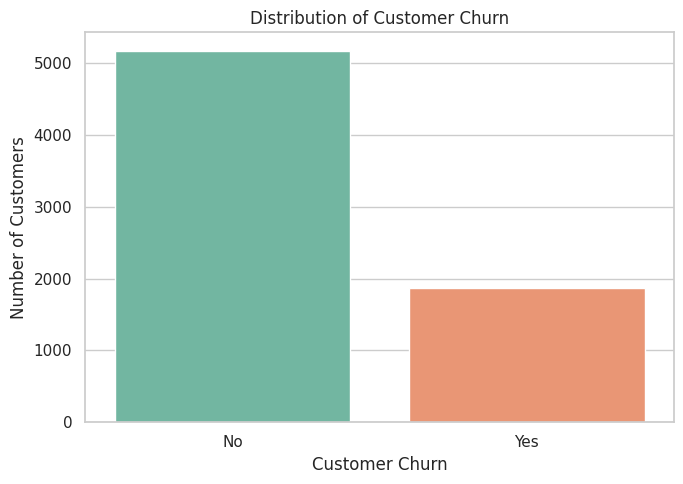

In [12]:
# Count plot
plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [13]:
# Calculate churn counts and percentages
churn_counts = eda_df["Churn"].value_counts()

churn_percentages = (
    eda_df["Churn"].value_counts(normalize=True) * 100
)

print("Churn counts:")
print(churn_counts)

print("\nChurn percentages:")
print(churn_percentages.round(2))

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


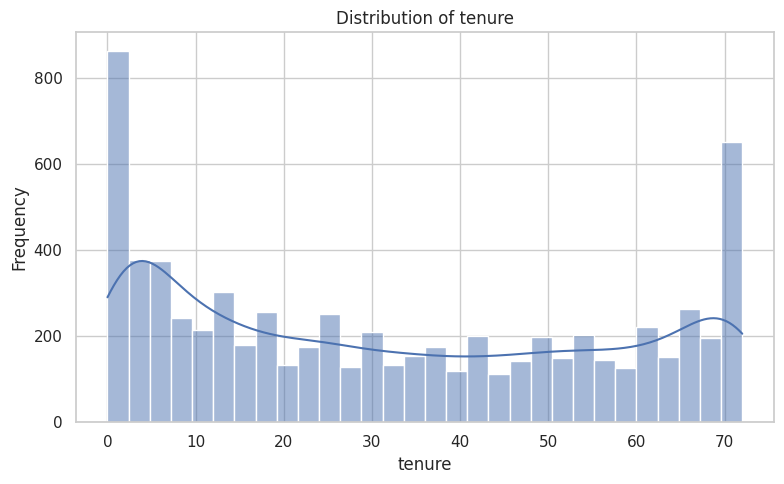

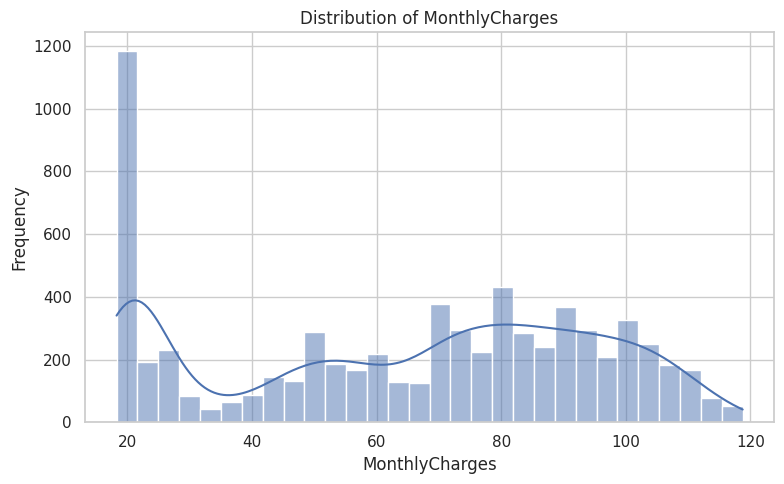

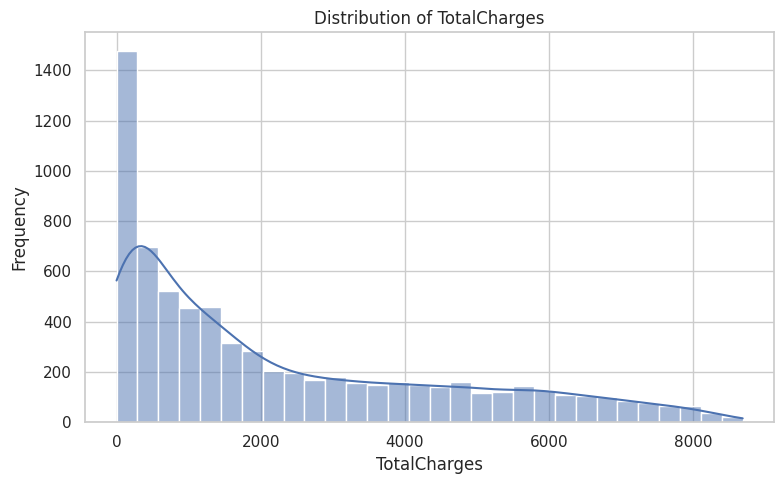

In [14]:
numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in numerical_cols:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=eda_df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

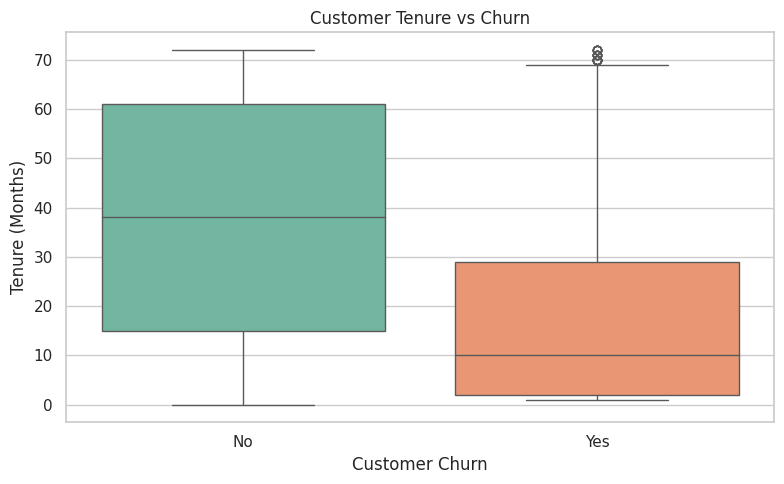

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

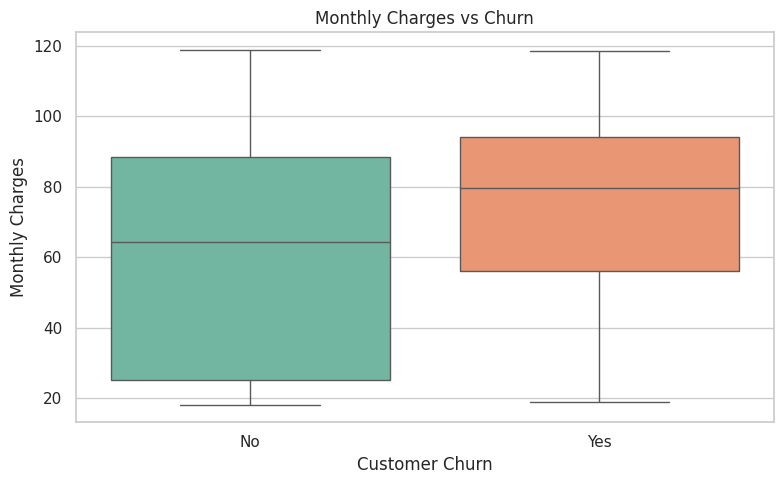

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

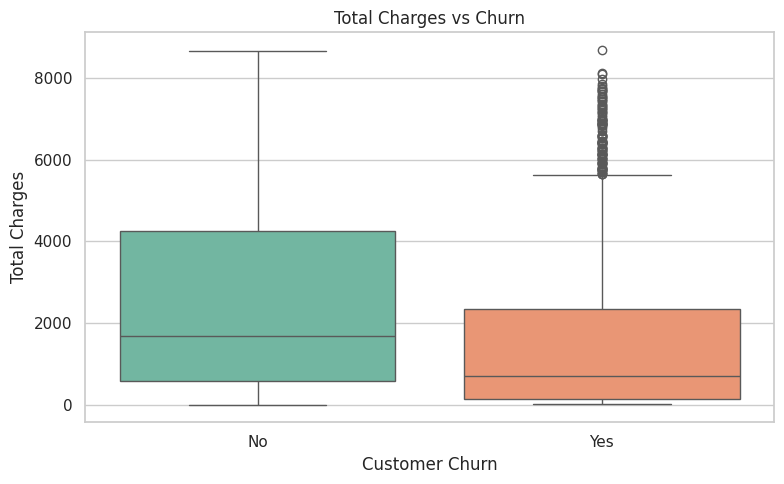

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="Churn",
    y="TotalCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Total Charges vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Total Charges")

plt.tight_layout()
plt.show()

In [18]:
# Compare average numerical values by churn status
churn_numeric_summary = eda_df.groupby("Churn")[
    numerical_cols
].agg(["mean", "median"])

display(churn_numeric_summary)

tenure        MonthlyCharges         TotalCharges          
            mean median           mean  median         mean    median
Churn                                                                
No     37.569965   38.0      61.265124  64.425  2549.911442  1679.525
Yes    17.979133   10.0      74.441332  79.650  1531.796094   703.550


Churn rate by Contract
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


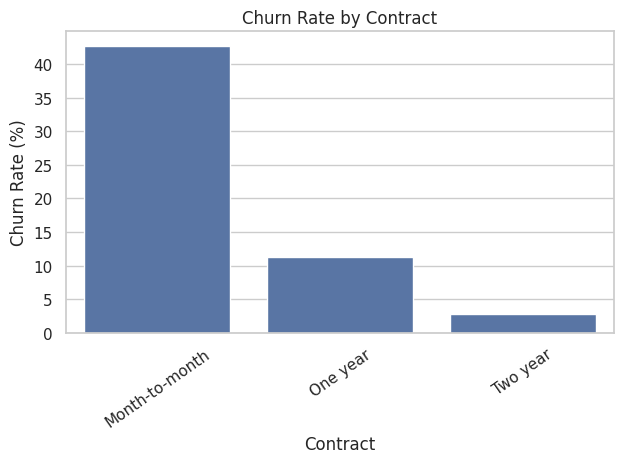


Churn rate by InternetService
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


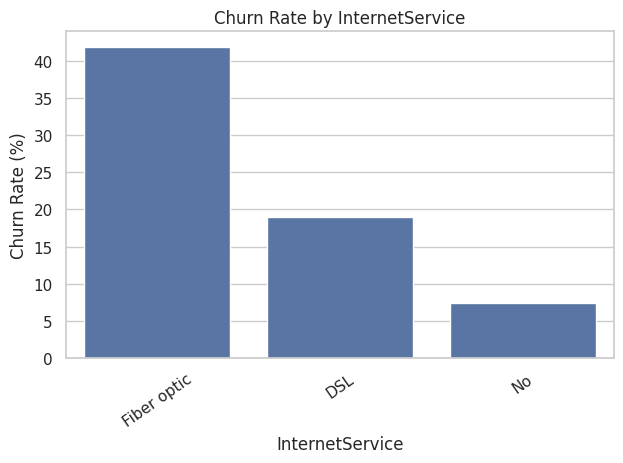


Churn rate by PaymentMethod
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


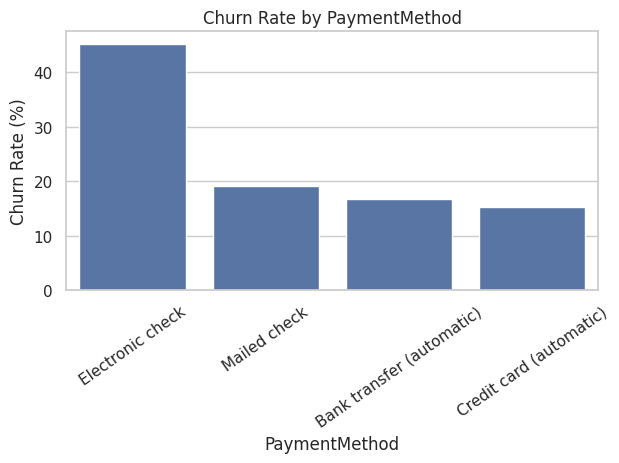


Churn rate by OnlineSecurity
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64


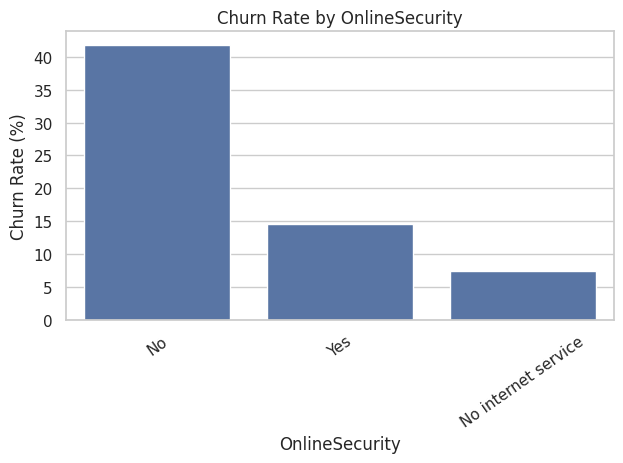


Churn rate by TechSupport
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


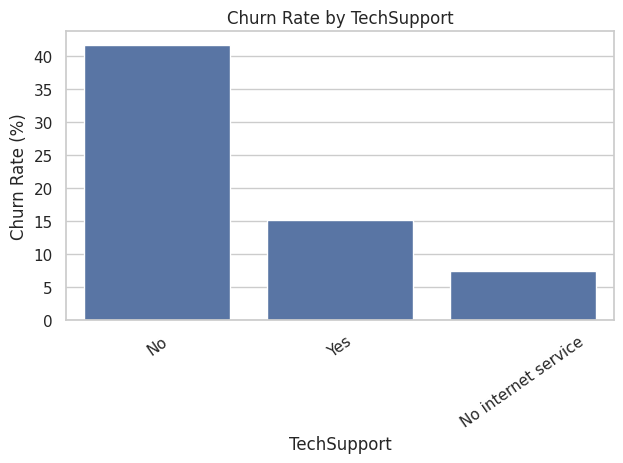


Churn rate by PaperlessBilling
PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


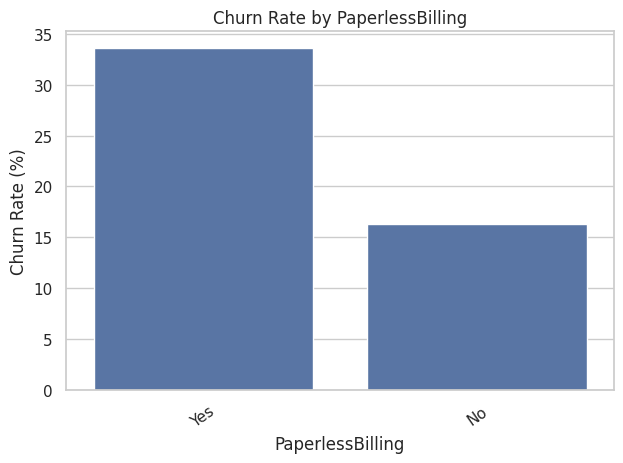


Churn rate by Partner
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64


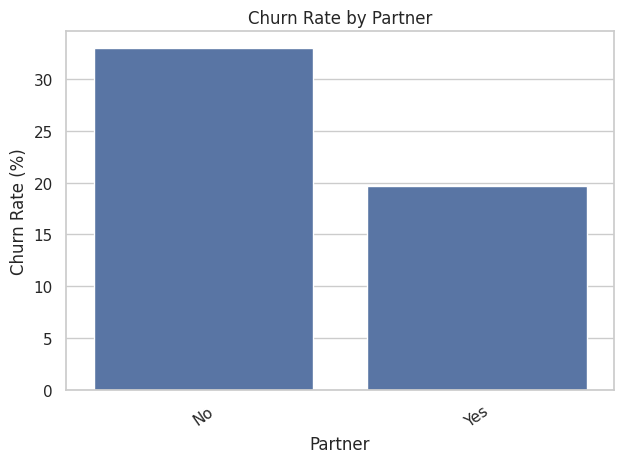


Churn rate by Dependents
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


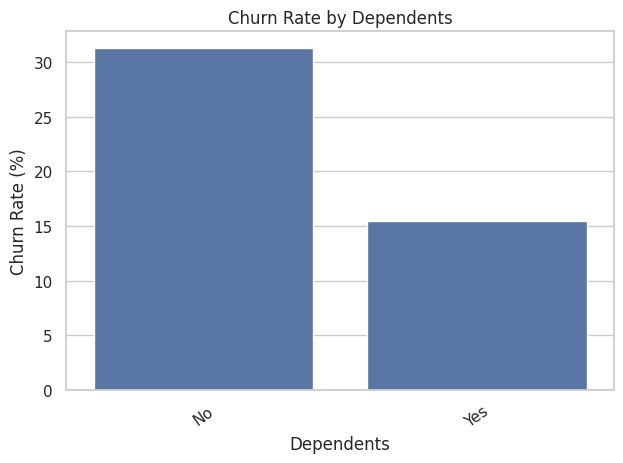

In [19]:
categorical_eda_cols = [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "PaperlessBilling",
    "Partner", "Dependents"
]

for col in categorical_eda_cols:

    churn_rate = eda_df.groupby(col)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    ).sort_values(ascending=False)

    print("\nChurn rate by", col)
    print(churn_rate.round(2))

    sns.barplot(x=churn_rate.index, y=churn_rate.values)
    plt.title("Churn Rate by " + col)
    plt.xlabel(col)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

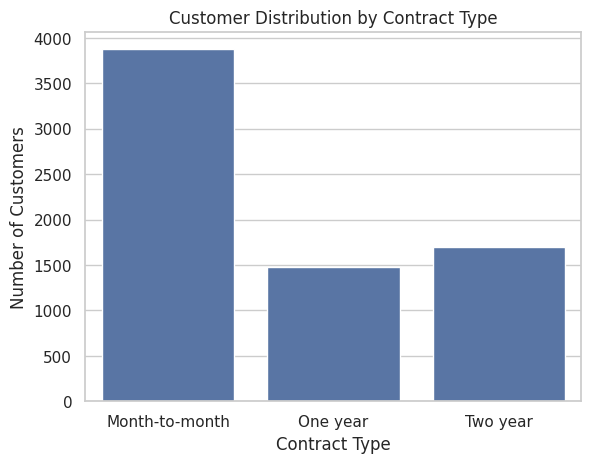

In [20]:
sns.countplot(data=eda_df, x="Contract")
plt.title("Customer Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

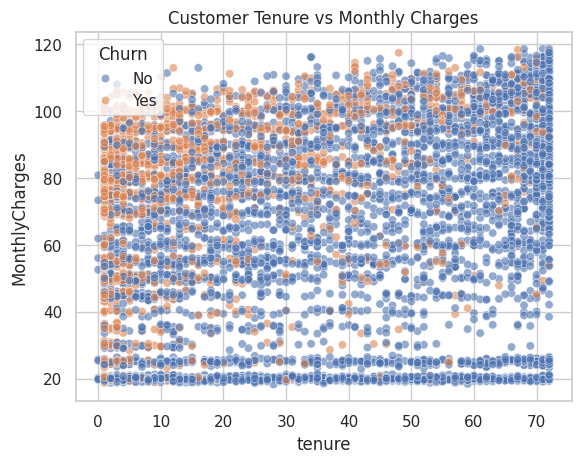

In [21]:
sns.scatterplot(
    data=eda_df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.6
)

plt.title("Customer Tenure vs Monthly Charges")
plt.show()

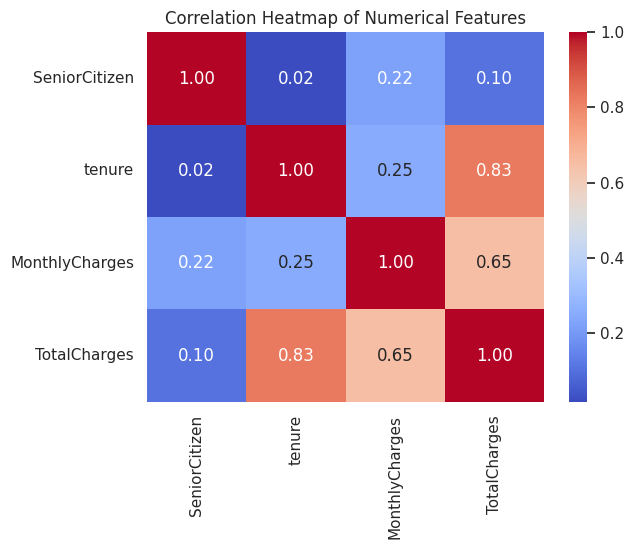

In [22]:
corr = eda_df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

InternetService    DSL  Fiber optic     No
Contract                                  
Month-to-month   32.22        54.61  18.89
One year          9.30        19.29   2.47
Two year          1.91         7.23   0.78


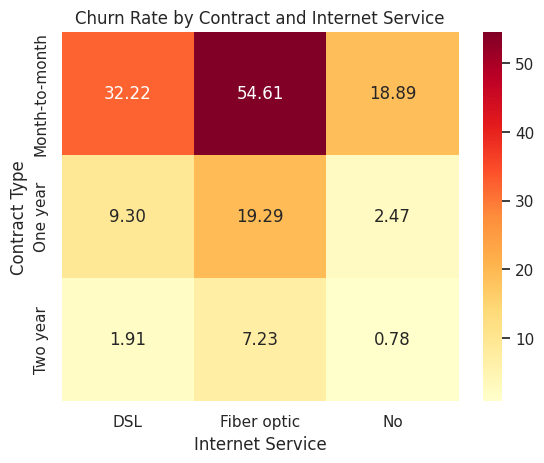

In [23]:
combined = eda_df.groupby(
    ["Contract", "InternetService"]
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).unstack()

print(combined.round(2))

sns.heatmap(combined, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Churn Rate by Contract and Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Contract Type")
plt.show()

In [24]:
summary = []

for col in categorical_eda_cols:

    rates = eda_df.groupby(col)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )

    for category, rate in rates.items():

        summary.append({
            "Feature": col,
            "Category": category,
            "Churn Rate (%)": round(rate, 2)
        })

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    by="Churn Rate (%)",
    ascending=False
)

print(summary_df.to_string(index=False))

         Feature                  Category  Churn Rate (%)
   PaymentMethod          Electronic check           45.29
        Contract            Month-to-month           42.71
 InternetService               Fiber optic           41.89
  OnlineSecurity                        No           41.77
     TechSupport                        No           41.64
PaperlessBilling                       Yes           33.57
         Partner                        No           32.96
      Dependents                        No           31.28
         Partner                       Yes           19.66
   PaymentMethod              Mailed check           19.11
 InternetService                       DSL           18.96
   PaymentMethod Bank transfer (automatic)           16.71
PaperlessBilling                        No           16.33
      Dependents                       Yes           15.45
   PaymentMethod   Credit card (automatic)           15.24
     TechSupport                       Yes           15.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7473385379701917
Confusion Matrix:
 [[866 169]
 [187 187]]
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.84      0.83      1035
           1       0.53      0.50      0.51       374

    accuracy                           0.75      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74      0.75      0.75      1409



Naive Bayes Accuracy: 0.6557842441447835

Confusion Matrix:
 [[600 435]
 [ 50 324]]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.58      0.71      1035
           1       0.43      0.87      0.57       374

    accuracy                           0.66      1409
   macro avg       0.67      0.72      0.64      1409
weighted avg       0.79      0.66      0.67      1409



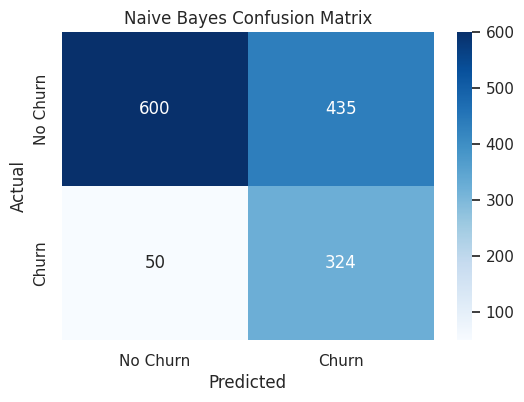

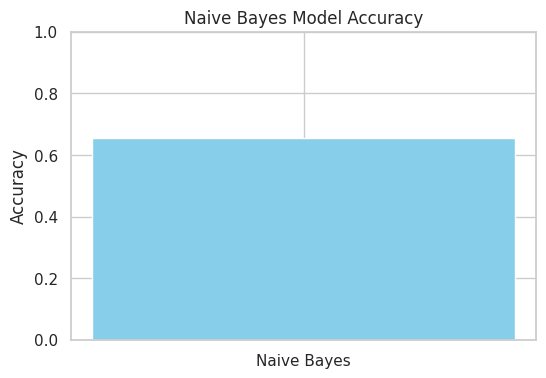

In [26]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

nb = GaussianNB()

nb.fit(X_train, y_train)

y_pred = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

accuracy = accuracy_score(y_test, y_pred)

plt.figure(figsize=(6, 4))
plt.bar(["Naive Bayes"], [accuracy], color="skyblue")
plt.ylabel("Accuracy")
plt.title("Naive Bayes Model Accuracy")
plt.ylim(0, 1)
plt.show()


In [27]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (

    accuracy_score,

    confusion_matrix,

    classification_report

)

# Separate features and target variable

X = df_model.drop("Churn", axis=1)

y = df_model["Churn"]

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(

    X, y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

# Feature scaling for models that require it

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [28]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("LOGISTIC REGRESSION")

print("Accuracy:", accuracy_score(y_test, lr_pred))

print("Confusion Matrix:\n", confusion_matrix(y_test, lr_pred))

print("Classification Report:\n", classification_report(y_test, lr_pred))

LOGISTIC REGRESSION
Accuracy: 0.8069552874378992
Confusion Matrix:
 [[925 110]
 [162 212]]
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [30]:
svm = SVC(kernel="rbf")

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("\nSUPPORT VECTOR MACHINE")

print("Accuracy:", accuracy_score(y_test, svm_pred))

print("Confusion Matrix:\n", confusion_matrix(y_test, svm_pred))

print("Classification Report:\n", classification_report(y_test, svm_pred))


SUPPORT VECTOR MACHINE
Accuracy: 0.7927608232789212
Confusion Matrix:
 [[934 101]
 [191 183]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [31]:


dt = DecisionTreeClassifier(

    criterion="gini",

    random_state=42

)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("\nDECISION TREE")

print("Accuracy:", accuracy_score(y_test, dt_pred))

print("Confusion Matrix:\n", confusion_matrix(y_test, dt_pred))

print("Classification Report:\n", classification_report(y_test, dt_pred))


DECISION TREE
Accuracy: 0.7260468417317246
Confusion Matrix:
 [[844 191]
 [195 179]]
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.82      0.81      1035
           1       0.48      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409



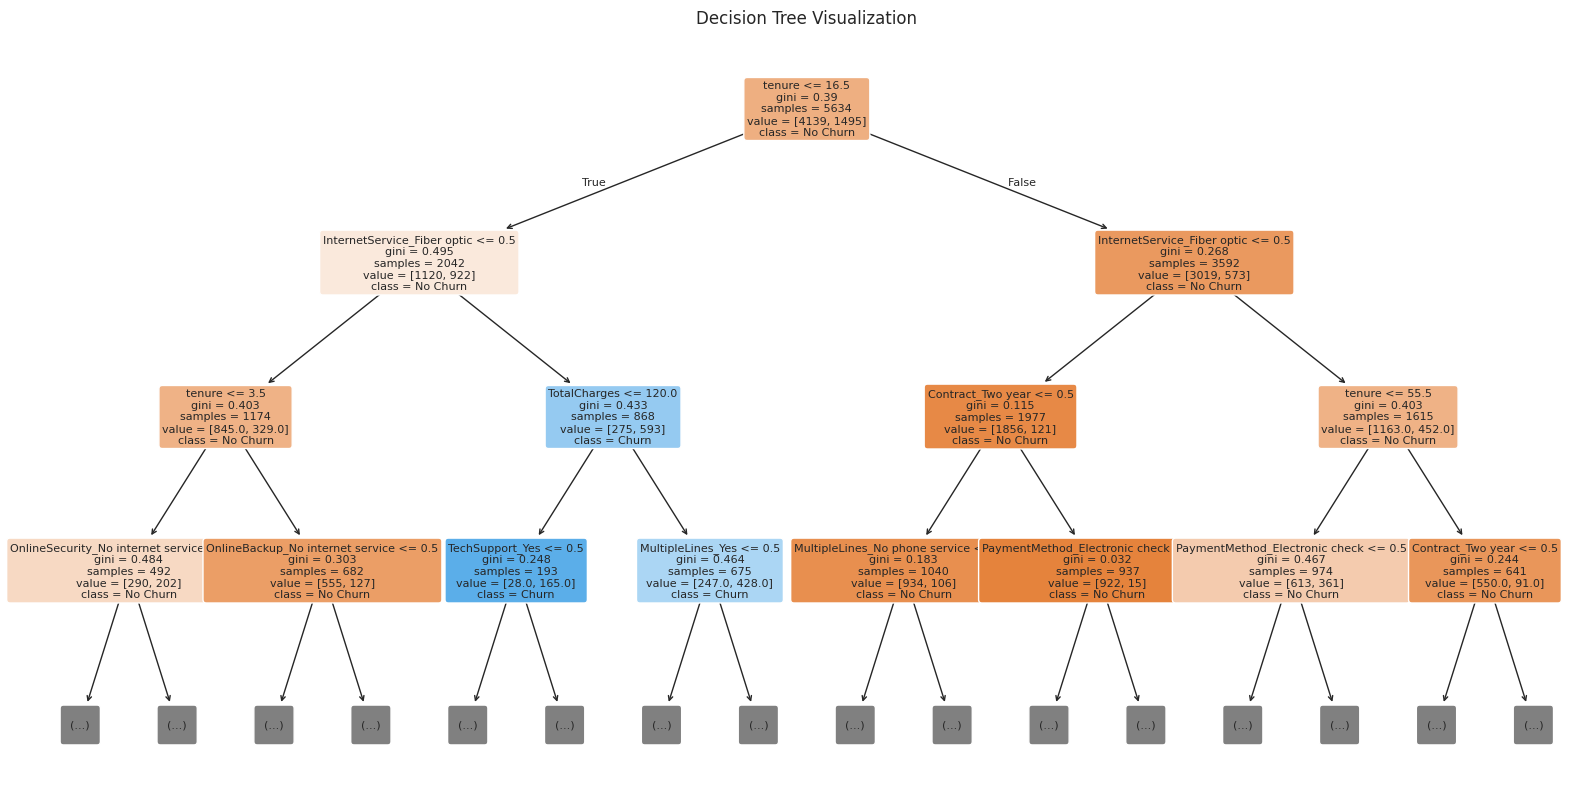

In [33]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

In [32]:


rf = RandomForestClassifier(

    n_estimators=100,

    random_state=42

)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("\nRANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, rf_pred))

print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))

print("Classification Report:\n", classification_report(y_test, rf_pred))


RANDOM FOREST
Accuracy: 0.7849538679914834
Confusion Matrix:
 [[920 115]
 [188 186]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.50      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



In [36]:
results = {
    "Logistic Regression": accuracy_score(y_test, lr_pred),
    "KNN": accuracy_score(y_test, knn_pred),
    "SVM": accuracy_score(y_test, svm_pred),
    "Decision Tree": accuracy_score(y_test, dt_pred),
    "Random Forest": accuracy_score(y_test, rf_pred),
    "Naive Bayes": accuracy_score(y_test, y_pred)
}

print("\nFINAL MODEL COMPARISON")

for model, accuracy in results.items():
    print(model, ":", round(accuracy * 100, 2), "%")


FINAL MODEL COMPARISON
Logistic Regression : 80.7 %
KNN : 74.73 %
SVM : 79.28 %
Decision Tree : 72.6 %
Random Forest : 78.5 %
Naive Bayes : 65.58 %


In [37]:
print("\nFINAL MODEL COMPARISON")

for model, accuracy in results.items():

    print(model, ":", round(accuracy * 100, 2), "%")


FINAL MODEL COMPARISON
Logistic Regression : 80.7 %
KNN : 74.73 %
SVM : 79.28 %
Decision Tree : 72.6 %
Random Forest : 78.5 %
Naive Bayes : 65.58 %


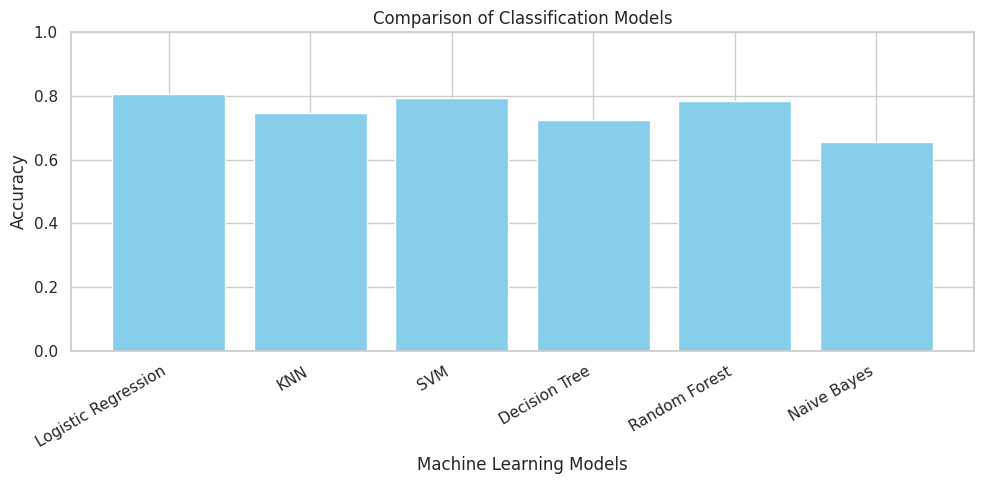

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(

    results.keys(),

    results.values(),

    color="skyblue"

)

plt.xlabel("Machine Learning Models")

plt.ylabel("Accuracy")

plt.title("Comparison of Classification Models")

plt.ylim(0, 1)

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.show()

